- minist dataset containing 70k digit images data of each 28 by 28 pixels
- X_train is a 3D array containg 60k images data , X_test containing 10k images data 
- X_train[0] to X_train[5999] contains one new image.

- y_train is the 1D array containing  digit values => array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)
- flatten layer converts the high dimensional data to 1D 


In [1]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense , Flatten

In [2]:
(X_train,y_train),(X_test,y_test) = keras.datasets.mnist.load_data()

In [ ]:
X_train.shape  # X_train is a 3D array with 60,000 rows of 28 by 28 pixels 

(60000, 28, 28)

In [11]:
X_train[0] # this is one image 

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [12]:
X_test.shape

(10000, 28, 28)

In [13]:
X_train[0].shape

(28, 28)

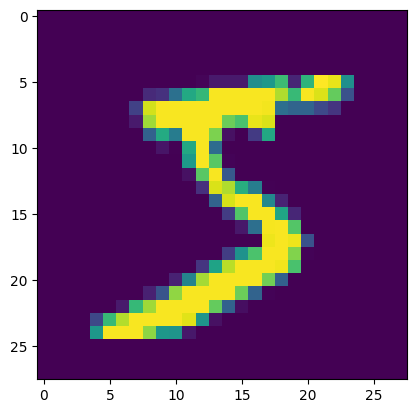

In [14]:
import matplotlib.pyplot as plt
plt.imshow(X_train[0])

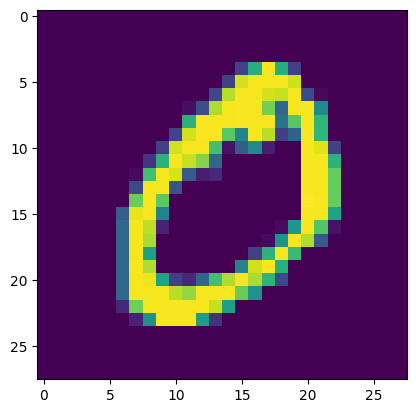

In [19]:
plt.imshow(X_train[1])

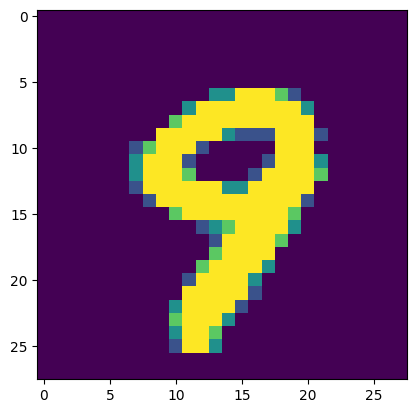

In [ ]:
plt.imshow(X_train[5999]) # last image in the X_train

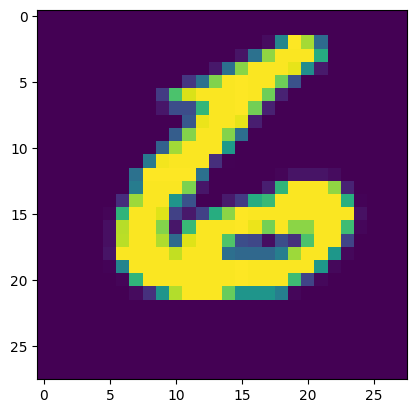

In [ ]:
plt.imshow(X_test[9999]) # last image in the X_test

In [22]:
X_train = X_train/255  # to standardise it between 0 & 1
X_test = X_test/255

In [26]:
y_train # gives array containing 60000 values 

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

In [ ]:
X_train[0]  # pixels in the range of 0 to 1

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [27]:
model = Sequential()
model.add(Flatten(input_shape=(28,28))) # 28 by 28 pixels are converted to 784 pixel in a 1D , in single row 
model.add(Dense(128,activation='relu'))
model.add(Dense(10,activation='softmax')) # always take softmax if you are dealing with multilabel classification data 

f:\desktop\ML\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [28]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
model.compile(loss="sparse_categorical_crossentropy",optimizer="Adam",metrics=['accuracy'])

In [63]:
history =model.fit(X_train,y_train,epochs=50,validation_split=0.2)

Epoch 1/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9982 - loss: 0.0052 - val_accuracy: 0.9777 - val_loss: 0.1199
Epoch 2/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9988 - loss: 0.0039 - val_accuracy: 0.9755 - val_loss: 0.1337
Epoch 3/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9985 - loss: 0.0047 - val_accuracy: 0.9745 - val_loss: 0.1396
Epoch 4/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9981 - loss: 0.0064 - val_accuracy: 0.9731 - val_loss: 0.1403
Epoch 5/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.9992 - loss: 0.0029 - val_accuracy: 0.9738 - val_loss: 0.1424
Epoch 6/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.9985 - loss: 0.0048 - val_accuracy: 0.9757 - val_loss: 0.1395
Epoch 7/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9990 - loss: 0.0034 - val_accuracy: 0.9749 - val_loss: 0.1445
Epoch 8/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9989 - loss: 0.

In [64]:
y_prob = model.predict(X_test) # it gives probabilites for all  the rows 

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


In [49]:
y_prob.shape

(10000, 10)

In [50]:
y_prob[0] # 1D array gives prob of each no. of 1st row in X_test

array([3.4088054e-12, 2.6146613e-18, 3.0765928e-12, 3.2092209e-09,
       1.5002280e-22, 2.0974796e-18, 1.1220762e-23, 1.0000000e+00,
       1.6062049e-13, 1.3012190e-12], dtype=float32)

In [65]:
y_pred = y_prob.argmax(axis=1)
y_pred

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

1st no in X_test According to my model is  : 7


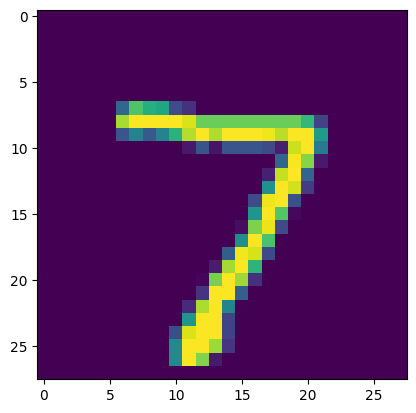

In [52]:
plt.imshow(X_test[0])
print("1st no in X_test According to my model is  :",y_pred[0])

In [53]:
from sklearn.metrics import accuracy_score

In [66]:
accuracy_score(y_test,y_pred)

0.9761

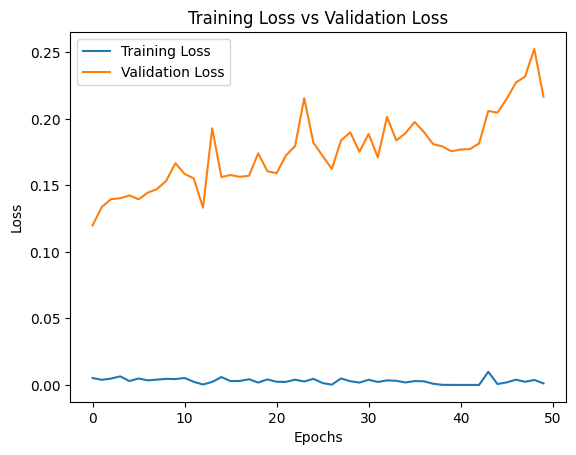

In [68]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss vs Validation Loss')

plt.legend()
plt.show()

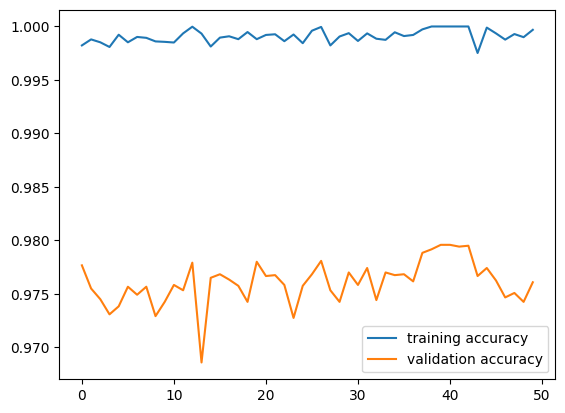

In [69]:
plt.plot(history.history['accuracy'],label="training accuracy")
plt.plot(history.history['val_accuracy'],label = 'validation accuracy')
plt.legend()
plt.show()